## **HR Employee Records Dataset**

### Business Context
Human Resources database containing employee master data with performance metrics and compensation information.

### Column Descriptions
1. **EmployeeID** - Unique employee identifier (EMP00001-EMP01900)
2. **FirstName** - Employee first name
3. **LastName** - Employee surname
4. **Department** - Department assignment (Sales, IT, HR, Finance, Operations, Marketing, R&D)
5. **Position** - Job title (Manager, Senior, Junior, Intern, Analyst, Engineer, Coordinator)
6. **JoinDate** - Hire date (mixed formats)
7. **BaseSalary** - Annual salary (with outliers)
8. **Bonus** - Annual bonus (mixed NULL representations)
9. **AgeYears** - Employee age (with negative values)
10. **Gender** - Gender identity (M, F, Other, NA)
11. **PerformanceRating** - Annual rating (mixed cases and formats)
12. **YearsExperience** - Total years in field
13. **ManagerID** - Direct manager's EmployeeID
14. **Email** - Work email (with duplicates)
15. **EmploymentStatus** - Active/Inactive/On Leave

### **Required Module**

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

### **Data Ingestion**

In [4]:
# File Path
file_path: str = '../../Data_Cleaning_and_Preprocessing/cleaned_data_sets/Production/production_employee_dataset.parquet'

# Let's define the function.
def dataingestion(file_path:str) -> pd.DataFrame:
    """This function will take the file path, read the file
    and returns the dataframe"""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f'[CRITICAL] File not found! {file_path}') 

    try:
        print(f'Loading data...')
        df = pd.read_parquet(file_path)

        print(f'[SUCCESS] Successfully loaded! Dataset contains {len(df)} rows.')
        return df
    except Exception as e:
        print(f"[CRITICAL ERROR] Failed to load the file {file_path} it may be corrupted. Details: {e}")
        raise # re-raise the error because the pipeline cannot continue without data

DataFrame: pd.DataFrame = dataingestion(file_path=file_path)


Loading data...
[SUCCESS] Successfully loaded! Dataset contains 1900 rows.


### **Let's preserve the original dataframe**

we'll use a copy of it to perform various operations.

In [7]:
emp_df: pd.DataFrame = DataFrame.copy()
print('[SUCCESS]')
emp_df.head()

[SUCCESS]


,EmployeeID,FirstName,LastName,Department,Position,JoinDate,BaseSalary,Bonus,AgeYears,Gender,PerformanceRating,YearsExperience,ManagerID,Email,EmploymentStatus
0,EMP00001,John,Johnson,Marketing,Coordinator,2022-01-28,41666.93,15507.62,22,F,Good,6,EMP00100,emp0@company.com,Inactive
1,EMP00002,Lisa,Miller,Finance,Analyst,2024-04-17,30000.00,24982.71,40,F,Average,21,EMP00089,emp1@company.com,On Leave
2,EMP00003,Sarah,Jones,HR,Analyst,2017-06-02,31812.89,20149.97,38,Other,Excellent,19,EMP00123,emp2@company.com,On Leave
3,EMP00004,David,Johnson,Marketing,Intern,2020-07-20,137792.77,5278.25,49,Not Specified,Below Average,28,EMP00047,emp3@company.com,Active
4,EMP00005,John,Davis,Sales,Coordinator,2018-04-08,93245.28,27541.43,33,Other,Excellent,26,EMP00146,emp4@company.com,On Leave


#### **Now we'll start the Analysis**

### **1. Univariate Analysis (The Baseline)**
_Focus: We must understand variables in isolation this phase is to hold with "shape" of our data._

- **Q1:** What is the distribution of `BaseSalary` across the entire company? (Are there massive outliers pulling the mean up?)

- **Q2:** What is the headcount breakdown by `Department`? (Which department is the largest?)

- **Q3:** How is the `PerformanceRating` distributed? (is the company grading on a strict bell curve, or is there grade inflation where everyone gets "Top Performer" rating?)

- **Q4:** What percentage of the workforce is currently Active vs. Inactive/On Leave (`EploymentStatus`)?

- **Q5:** What does the age distribution (`AgeYears`) look like for the workforce?

#### **Q1: What is the distribution of `BaseSalary` across the entire company?** (Are there massive outliers pulling the mean up?)

We'll use the histogram plot for it, for outliers we can get a quick check for it by `df.describe()` it'll give us the min and max value, mean and other statistical summary for numerical columns.

but outliers are always based in terms of business logic, if we look at the salaries for employees $200,000 might look at an outliers with respect to average but it might be a salary for any senior executive such as CEO, MD etc.

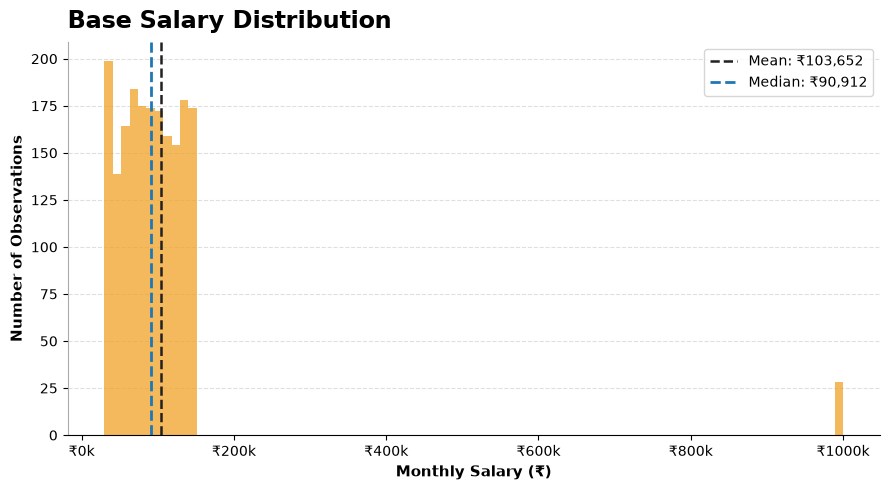

In [33]:
import matplotlib.ticker as ticker

# Let's plot a histogram.

# Initiating the fig and axes.
fig, ax = plt.subplots(figsize=(9, 5))

# plotting the hist
ax.hist(
    emp_df['BaseSalary'],
    bins='auto',
    # edgecolor='black',
    alpha=0.75,
    color='#f1a226'
)

# Titles and labels
ax.set_title(
    'Base Salary Distribution',
    fontsize=17,
    fontweight='bold',
    pad=10,
    loc='left'
)

ax.set_xlabel('Monthly Salary (₹)', fontsize=11, fontweight='bold')
ax.set_ylabel('Number of Observations', fontsize=11, fontweight='bold')

# Format X-axis
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: f'₹{x/1000:.0f}k'
    )
)
# Grid
ax.grid(axis='y', linestyle='--', alpha=0.4)

# Keep grid behind bars
ax.set_axisbelow(True)

# Remove unnecessary borders.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['left'].set_color('#aaaaaa')

# let's add vlines on mean and median of the following distribution.
salary_mean = emp_df['BaseSalary'].mean().item()
salary_median = emp_df['BaseSalary'].median().item()

ax.axvline(
    salary_mean,
    linestyle='--',
    linewidth=1.8,
    label=f'Mean: ₹{salary_mean:,.0f}',
    color='#222021'
)

ax.axvline(
    salary_median,
    linestyle='--',
    linewidth=2,
    label=f'Median: ₹{salary_median:,.0f}'
)

ax.legend()

plt.tight_layout()
plt.show()

Yes there are almost 27 such employees that hold salary of around Rs 10,00,000, (Raise an inquery) to the management before labeling them outliers.

The mean of the salary is notably higher than median salary of almost Rs 13,000. Due to those massive values.

Most of the employees salary falls between Rs 25,000 to Rs 1,70,000 range.

#### **Q2: What is the headcount breakdown by `Department`?** (Which department is the largest?)

We'll use `value counts` for this, since `Department` is a categorical columns.

In [63]:
department_count = emp_df['Department'].value_counts()
department_count = department_count.sort_values()
department_count

Department
Operations    247
R&D           256
Marketing     268
HR            269
Finance       270
Sales         280
IT            310
Name: count, dtype: int64

**Let's visualize it via barplot**

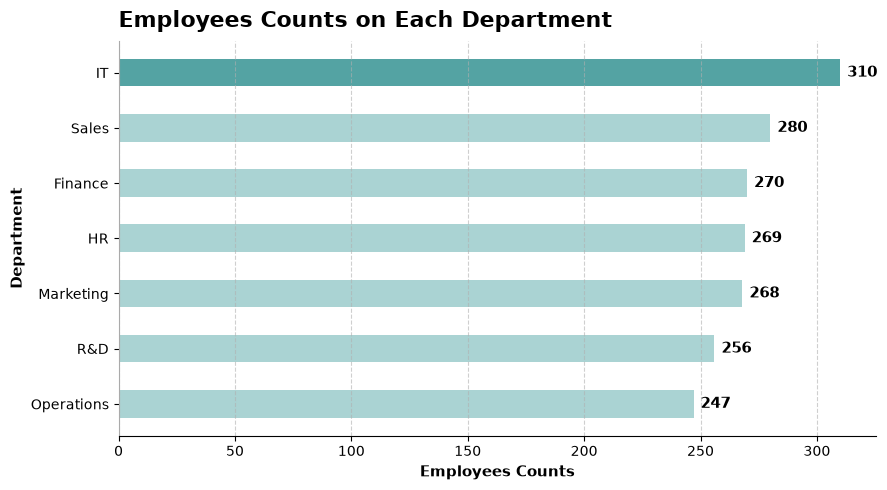

In [76]:
# Initiating the figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

colors_list =['#95c8c8'] * len(department_count)
colors_list[-1] = '#298c8c'

bar = ax.barh(
    department_count.index,
    department_count.values,
    height=0.5,
    alpha=0.8,
    color= colors_list
)

# titles and labels
ax.set_title('Employees Counts on Each Department', fontsize=16, fontweight='bold', pad=10, loc='left')
ax.set_xlabel('Employees Counts', fontsize=11, fontweight='bold')
ax.set_ylabel('Department', fontsize=11, fontweight='bold')

# spines 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['right'].set_color('#aaaaaa')

# grid
ax.grid(axis='x', linestyle='--', alpha=0.6)

# set bar label
ax.bar_label(bar, fontsize=11, fontweight='bold', padding=5)
plt.tight_layout()
plt.show()

The **IT Department** is the largest department, has **310 Employees**, Sales at the second place consists of 280 Employees.

#### **Q3: How is the `PerformanceRating` distributed?** (is the company grading on a strict bell curve, or is there grade inflation where everyone gets "Top Performer" rating?)



PerformanceRating
Average          485
Excellent        477
Good             475
Below Average    463
Name: count, dtype: int64